In [1]:
import sys
import os
import importlib.util
project_dir = r"C:\Users\douga\Documents\Y4 Project"
sys.path.insert(0, project_dir)
sys.modules.pop("scripts", None)
import numpy as np
import pickle
import json
import corner
import jax
import matplotlib.pyplot as plt
import ultranest
import tinygp
import ipywidgets

from scripts import pitchfork_compile, pitchfork_sampler, posterior_plot

In [2]:
pitchfork_dir = os.path.join(project_dir, "pitchfork")

with open(os.path.join(pitchfork_dir, "pitchfork.json"), "r") as fp:
    pitchfork_dict = json.load(fp)

with open(os.path.join(pitchfork_dir, "pitchfork_info.json"), "r") as fp:
    pitchfork_info = json.load(fp)

pitchfork_cov = np.loadtxt(
    os.path.join(pitchfork_dir, "pitchfork_covariance.txt")
)

pitchfork = pitchfork_compile(pitchfork_dict, pitchfork_info)



In [3]:
# sampler = pitchfork_sampler(pitchfork, pitchfork_cov)
# priors = sampler.priors

# labels = ['initial_mass', 'initial_Zinit', 'initial_Yinit', 'initial_MLT', 'star_age', 'a', 'b']

# size = 10000
# prior_samples = np.array([prior.rvs(size=size) for prior in priors])

In [6]:
# project_dir = r"C:\Users\douga\Documents\Y4 Project"
# os.chdir(project_dir)

# star_name = '16CygB'
# results = sampler(star_name, save_as='16CygB_results.pkl')

[pitchfork_sampler] sampling posterior of 16CygB!
[pitchfork_sampler] GP params: gp_var=4, gp_ls_factor=7
[pitchfork_sampler] Considering freqs in range: 13 ≤ n ≤ 27
[ultranest] Sampling 400 live points from prior ...


[ultranest] Explored until L=-9  63 [-9.1033..-9.1026]*| it/evals=7409/316743 eff=3.0056% N=400           0 0 0 0 
[ultranest] Likelihood function evaluations: 316743
[ultranest]   logZ = -22.9 +- 0.1375
[ultranest] Effective samples strategy satisfied (ESS = 2501.2, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.05 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.14, need <0.5)
[ultranest]   logZ error budget: single: 0.17 bs:0.14 tail:0.01 total:0.14 required:<0.50
[ultranest] done iterating.
[pitchfork_sampler] finished in 77m 59.8s!


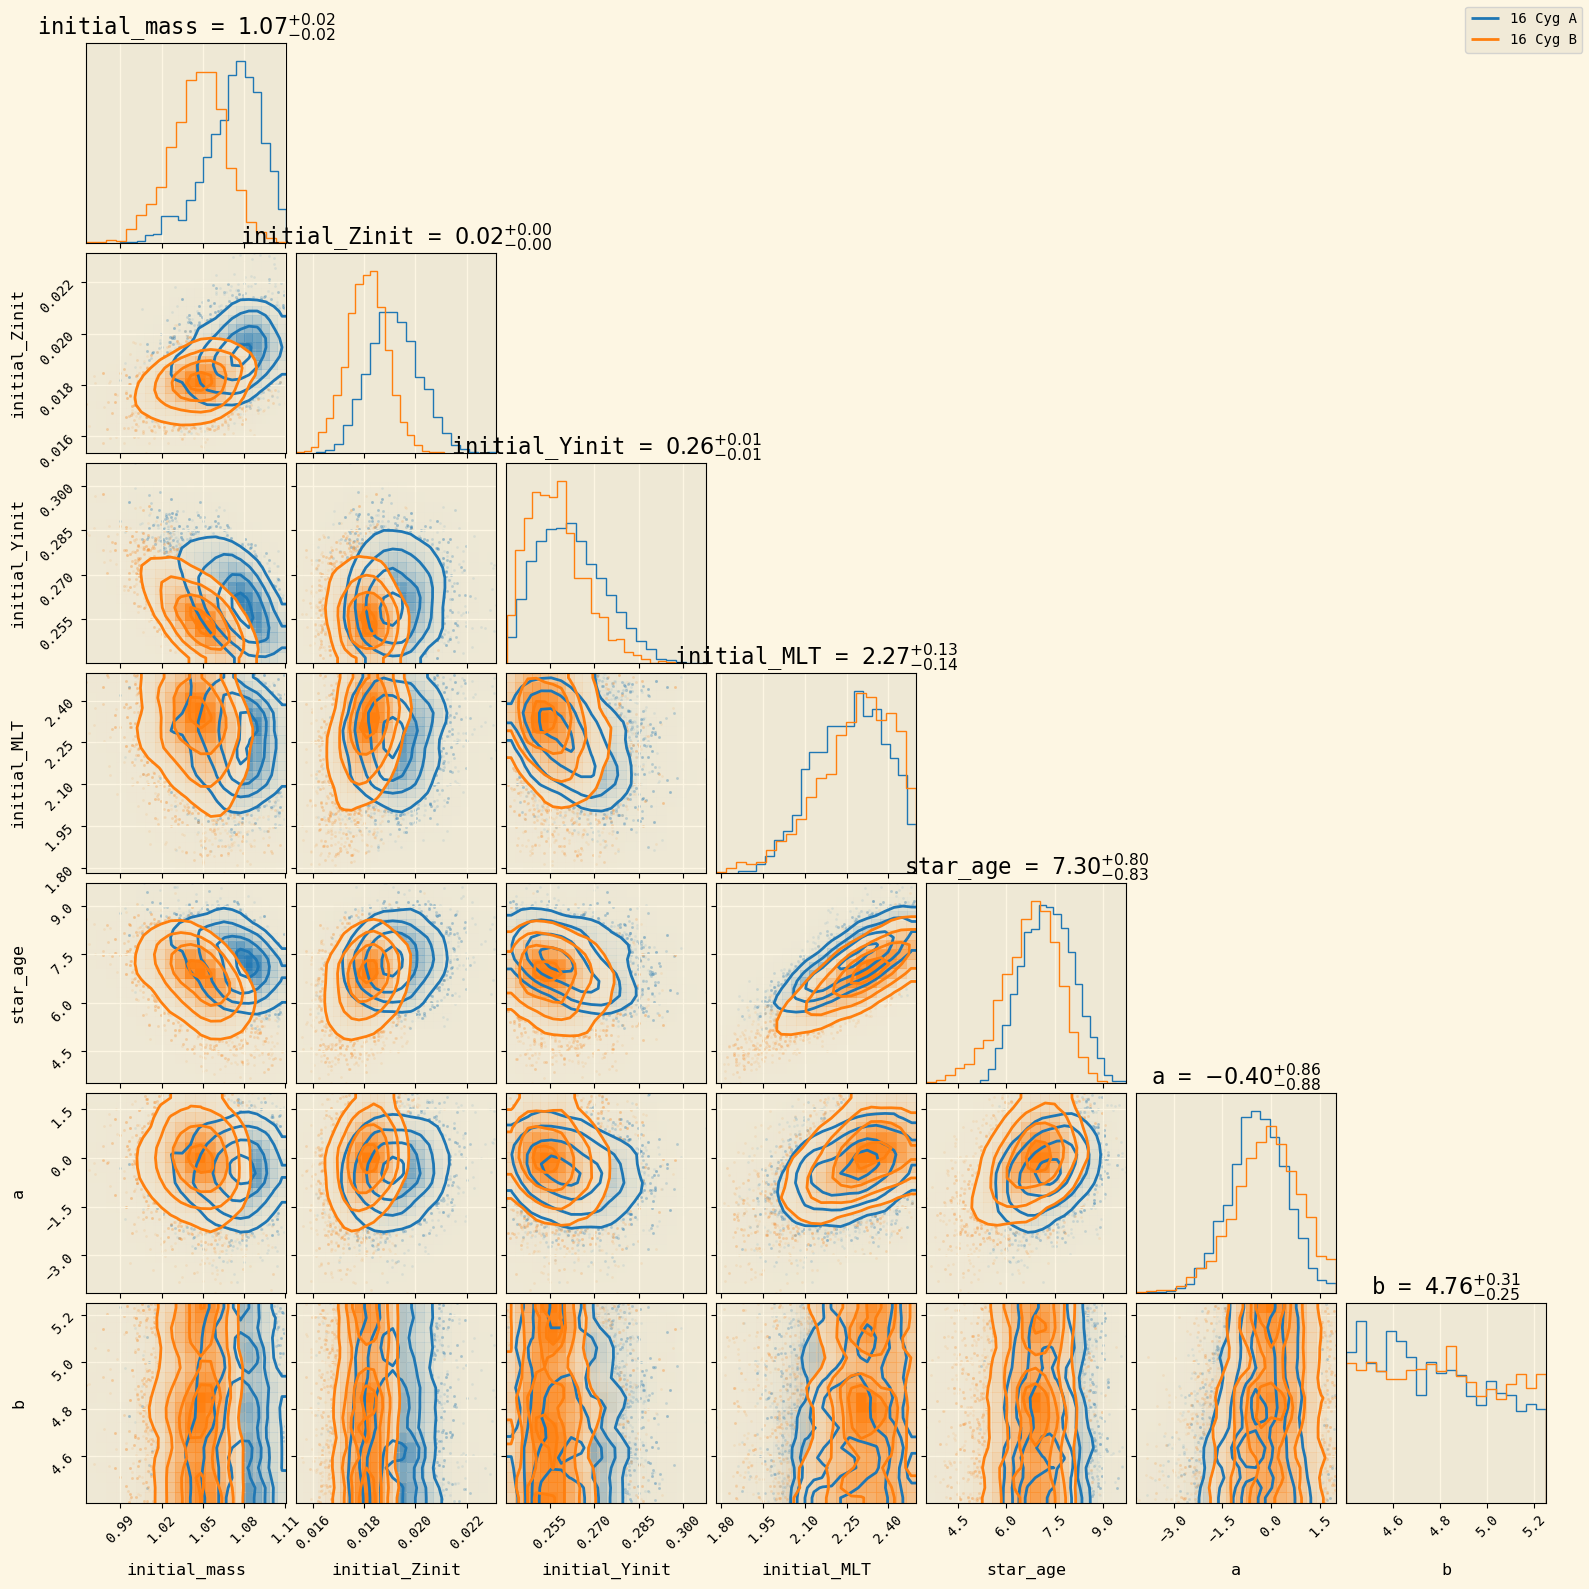

In [3]:
os.chdir(r"C:\Users\douga\Documents\Y4 Project")

with open('stars/16CygA/16CygA_results.pkl', 'rb') as fp:
    results_A = pickle.load(fp)

with open('stars/16CygB/16CygB_results.pkl', 'rb') as fp:
    results_B = pickle.load(fp)

# Extract posterior samples
# Check the structure of results if these keys are not correct
samples_A_nonuni = results_A["samples"]
samples_B_nonuni = results_B["samples"]

labels = [
    'initial_mass',
    'initial_Zinit',
    'initial_Yinit',
    'initial_MLT',
    'star_age',
    'a',
    'b'
]

# # Plot both posterior distributions on the same figure
# fig = corner.corner(
#     samples_A_nonuni,
#     labels=labels,
#     color="tab:blue",
#     smooth=True,
#     hist_kwargs={"density": True},
#     show_titles=True
# )

# corner.corner(
#     samples_B_nonuni,
#     labels=labels,
#     color="tab:orange",
#     smooth=True,
#     hist_kwargs={"density": True},
#     fig=fig,
#     show_titles=False
# )

# # Add legend
# handles = [
#     plt.Line2D([], [], color="tab:blue", label="16 Cyg A"),
#     plt.Line2D([], [], color="tab:orange", label="16 Cyg B")
# ]
# fig.legend(handles=handles, loc="upper right")

# plt.show()

In [13]:
from scripts import beta_prior, uniform_prior

mass_prior = beta_prior(0.8, 1.2, a=1, b=1) #<- default: beta_prior(0.8, 1.2, a=5, b=2)

Zinit_prior = beta_prior(0.004, 0.038, a=1, b=1) #<- default: beta_prior(0.004, 0.038, a=2, b=5)

Yinit_prior = beta_prior(0.24, 0.32, a=1, b=1) #<- default: beta_prior(0.24, 0.32, a=2, b=5)

MLT_prior = beta_prior(1.7, 2.5, a=1, b=1) #<- default: beta_prior(1.7, 2.5, a=1.2, b=1.2)

age_prior = beta_prior(0.03, 14, a=1, b=1) #<- default: beta_prior(0.03, 14, a=1.2, b=1.2)

a_prior = uniform_prior(-10, 2) #<- default: uniform_prior(-10, 2)

b_prior = uniform_prior(4.4, 5.25) #<- default: uniform_prior(4.4, 5.25)

custom_priors = [mass_prior, Zinit_prior, Yinit_prior, MLT_prior, age_prior, a_prior, b_prior]

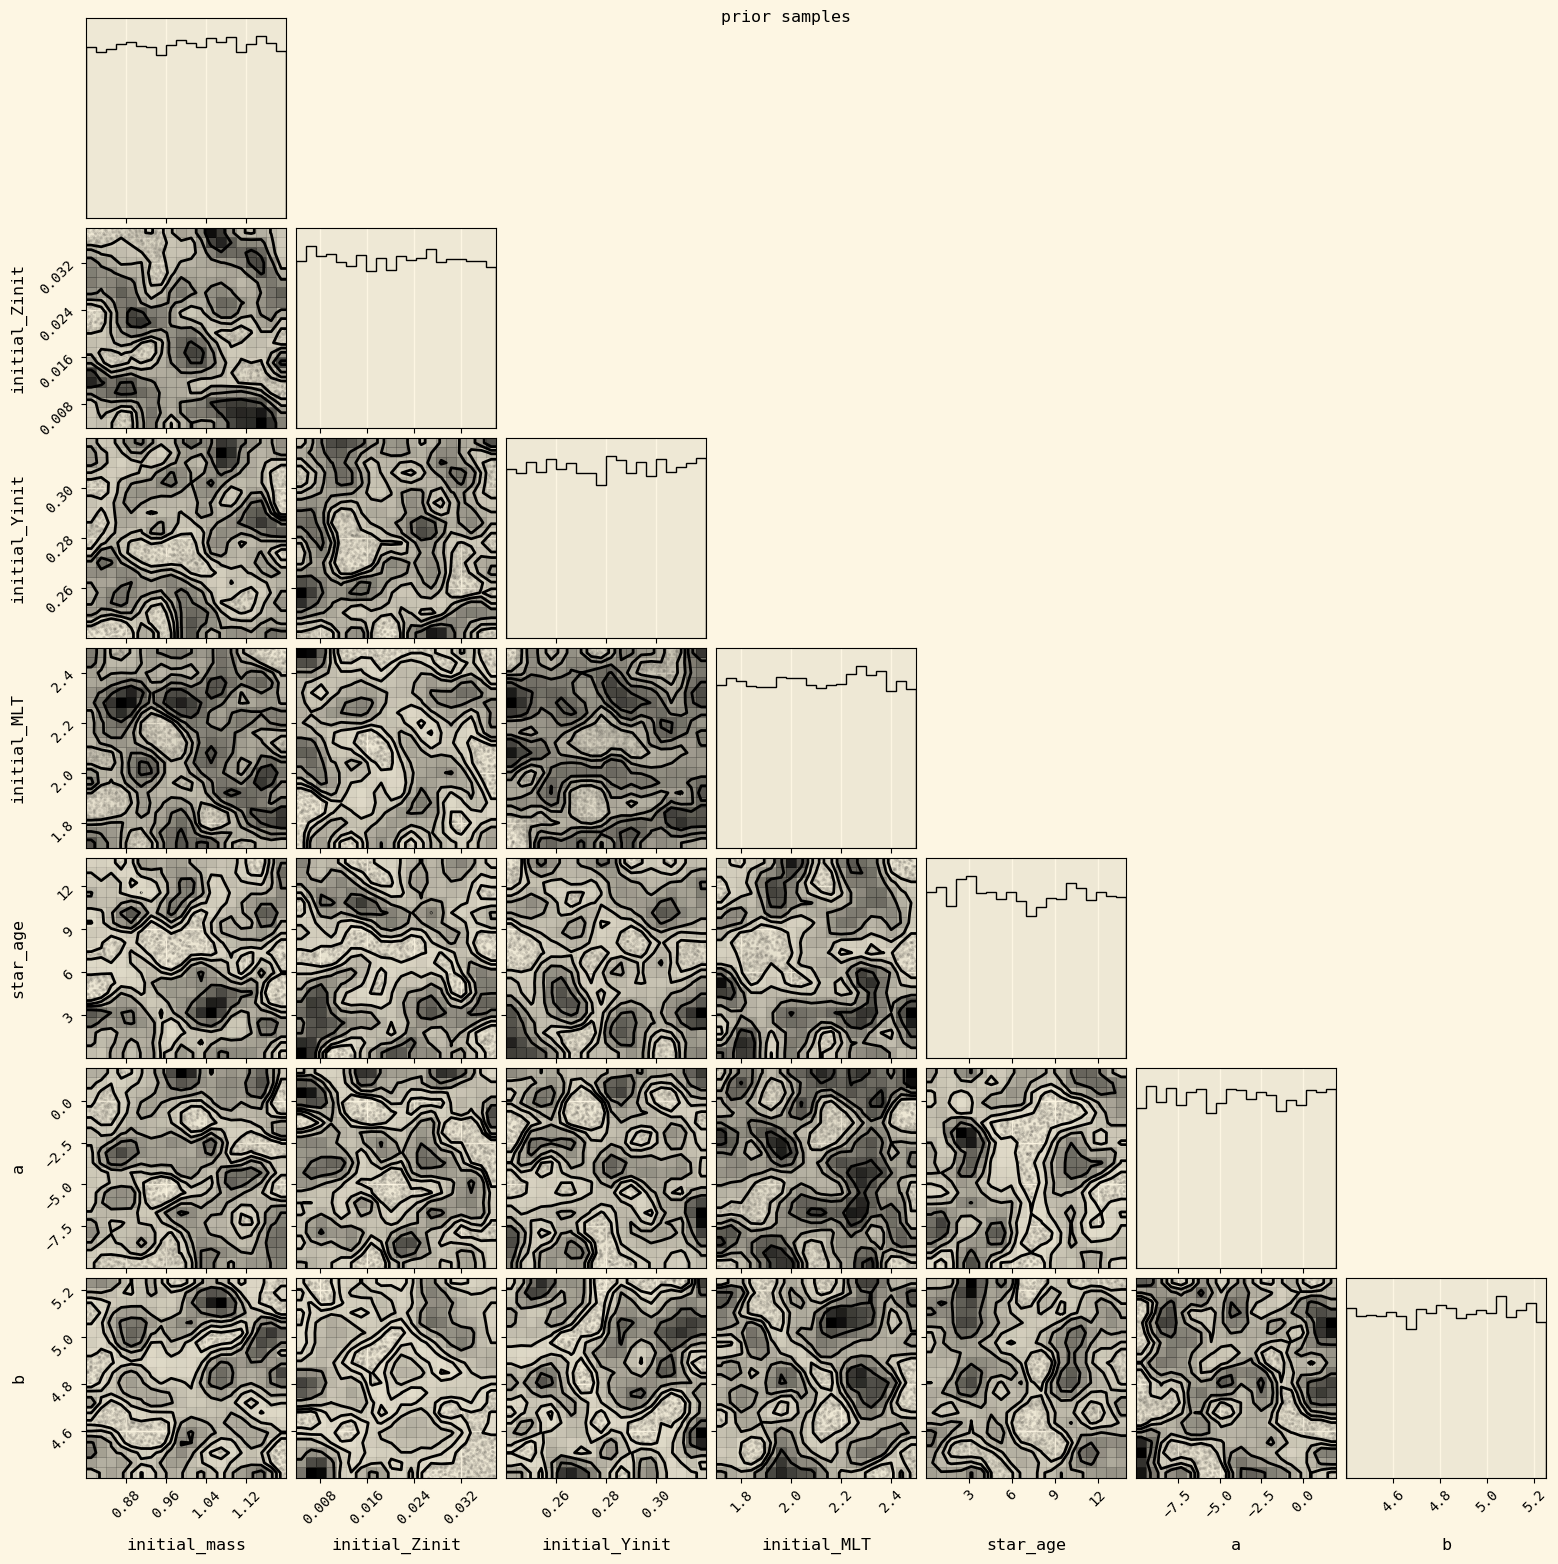

In [14]:
sampler = pitchfork_sampler(pitchfork, pitchfork_cov, priors=custom_priors)

priors = sampler.priors

labels = ['initial_mass', 'initial_Zinit', 'initial_Yinit', 'initial_MLT', 'star_age', 'a', 'b']

size = 10000
prior_samples = np.array([prior.rvs(size=size) for prior in priors])

corner.corner(prior_samples.T, color='black', labels = labels, hist_kwargs={'density':True}, smooth=True);
plt.suptitle('prior samples')
plt.show()

In [15]:
star_name = "16CygA"

results = sampler(star_name, save_as='16CygA_uni_results.pkl')

[pitchfork_sampler] sampling posterior of 16CygA!
[pitchfork_sampler] GP params: gp_var=4, gp_ls_factor=7
[pitchfork_sampler] Considering freqs in range: 12 ≤ n ≤ 27
[ultranest] Sampling 400 live points from prior ...


[ultranest] Explored until L=-1e+01   [-10.7317..-10.7316]*| it/evals=7649/565390 eff=1.3538% N=400    0        
[ultranest] Likelihood function evaluations: 565390
[ultranest]   logZ = -25.15 +- 0.1026
[ultranest] Effective samples strategy satisfied (ESS = 2284.5, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.07 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.10, need <0.5)
[ultranest]   logZ error budget: single: 0.18 bs:0.10 tail:0.01 total:0.10 required:<0.50
[ultranest] done iterating.
[pitchfork_sampler] finished in 30m 42.5s!


[pitchfork_sampler] sampling posterior of 16CygB!
[pitchfork_sampler] GP params: gp_var=4, gp_ls_factor=7
[pitchfork_sampler] Considering freqs in range: 13 ≤ n ≤ 27
[ultranest] Sampling 400 live points from prior ...


[ultranest] Explored until L=-9  68 [-9.0769..-9.0768]*| it/evals=7977/262017 eff=3.0491% N=400        0  0 0 0 
[ultranest] Likelihood function evaluations: 262017
[ultranest]   logZ = -24.29 +- 0.115
[ultranest] Effective samples strategy satisfied (ESS = 2541.6, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.47+-0.10 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.12, need <0.5)
[ultranest]   logZ error budget: single: 0.18 bs:0.12 tail:0.01 total:0.12 required:<0.50
[ultranest] done iterating.
[pitchfork_sampler] finished in 8m 3.0s!


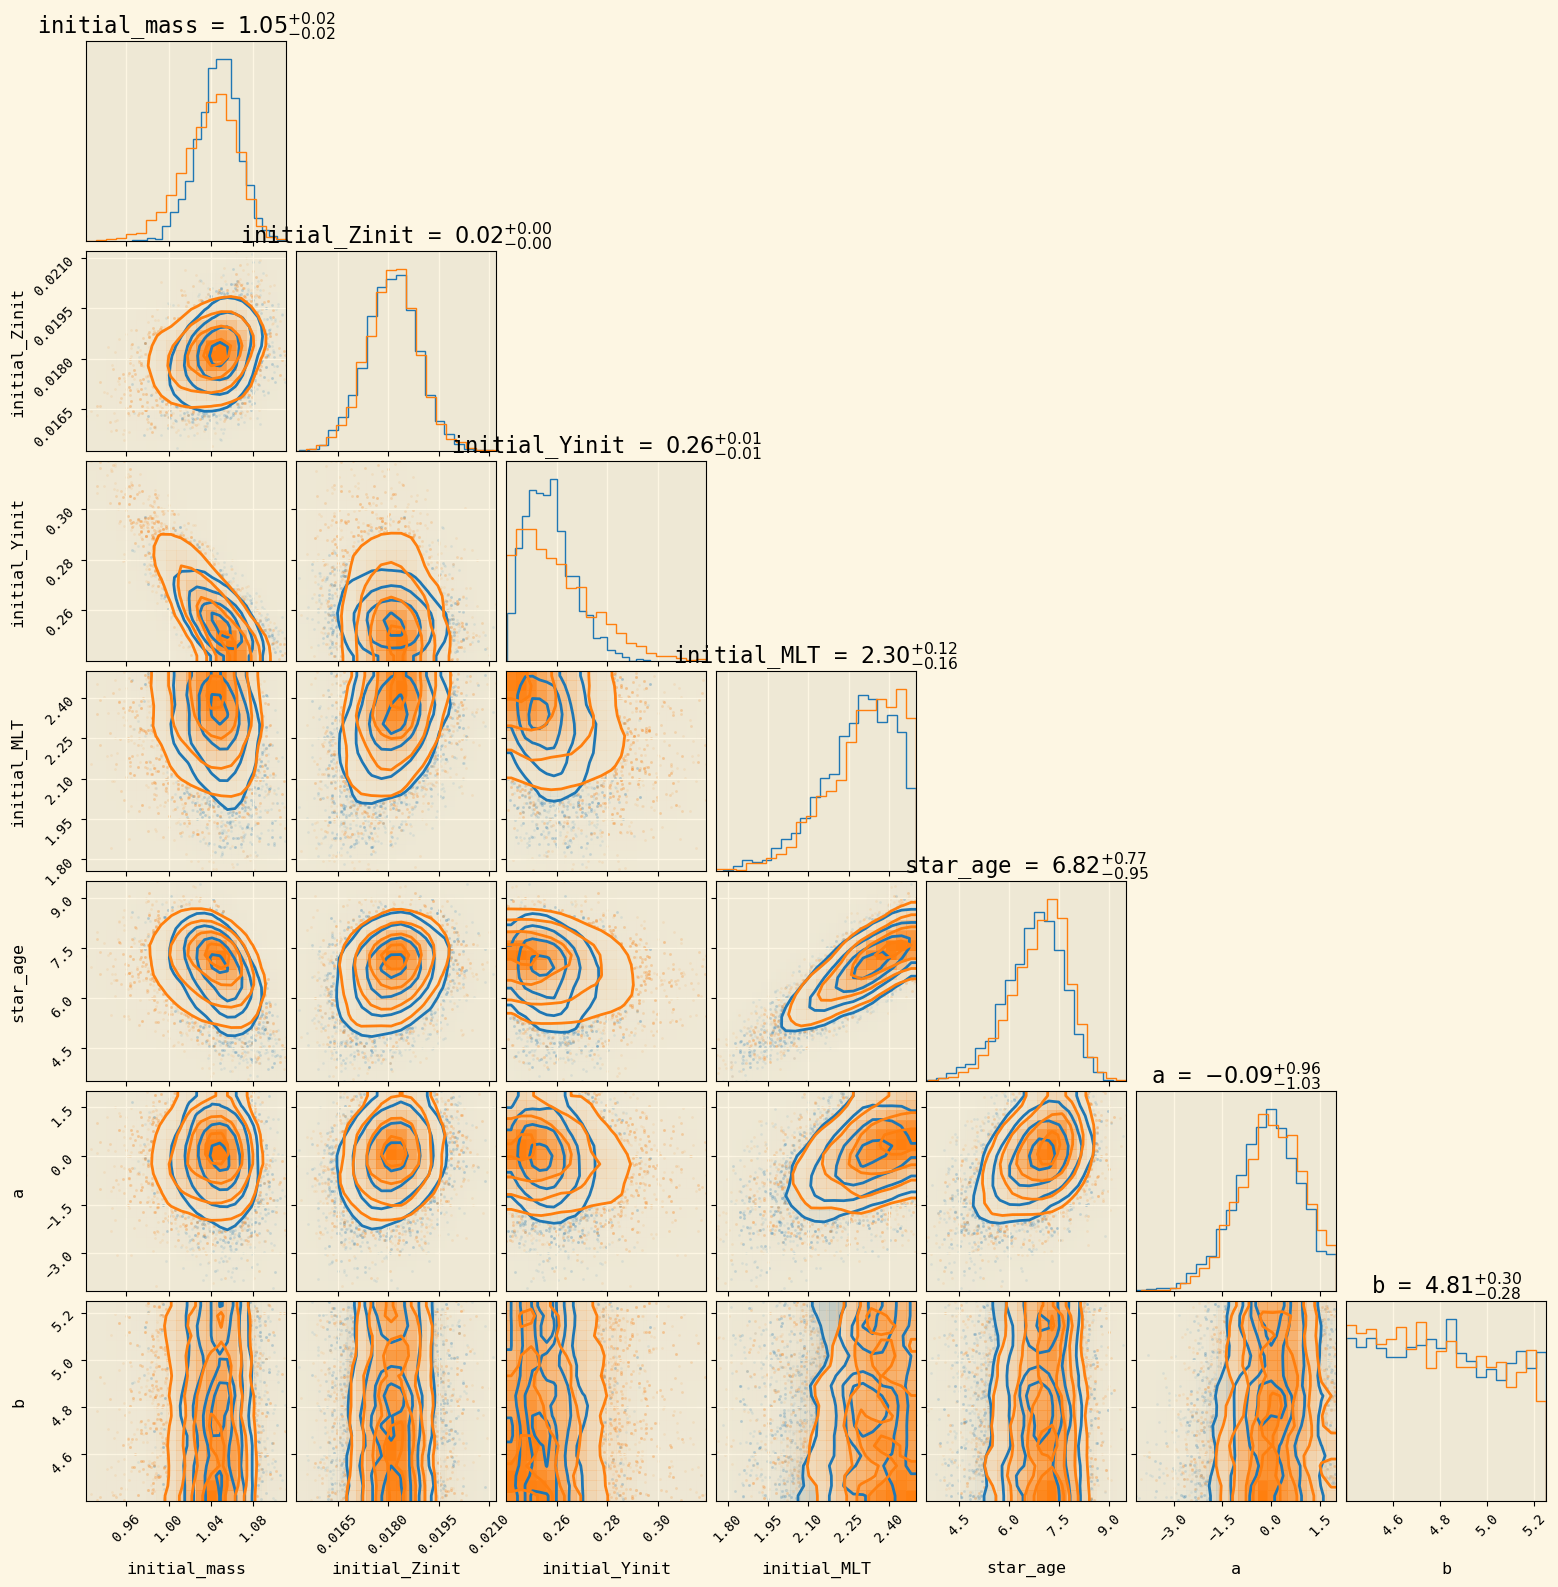

In [17]:
star_name = "16CygB"

results = sampler(star_name, save_as='16CygB_uni_results.pkl')

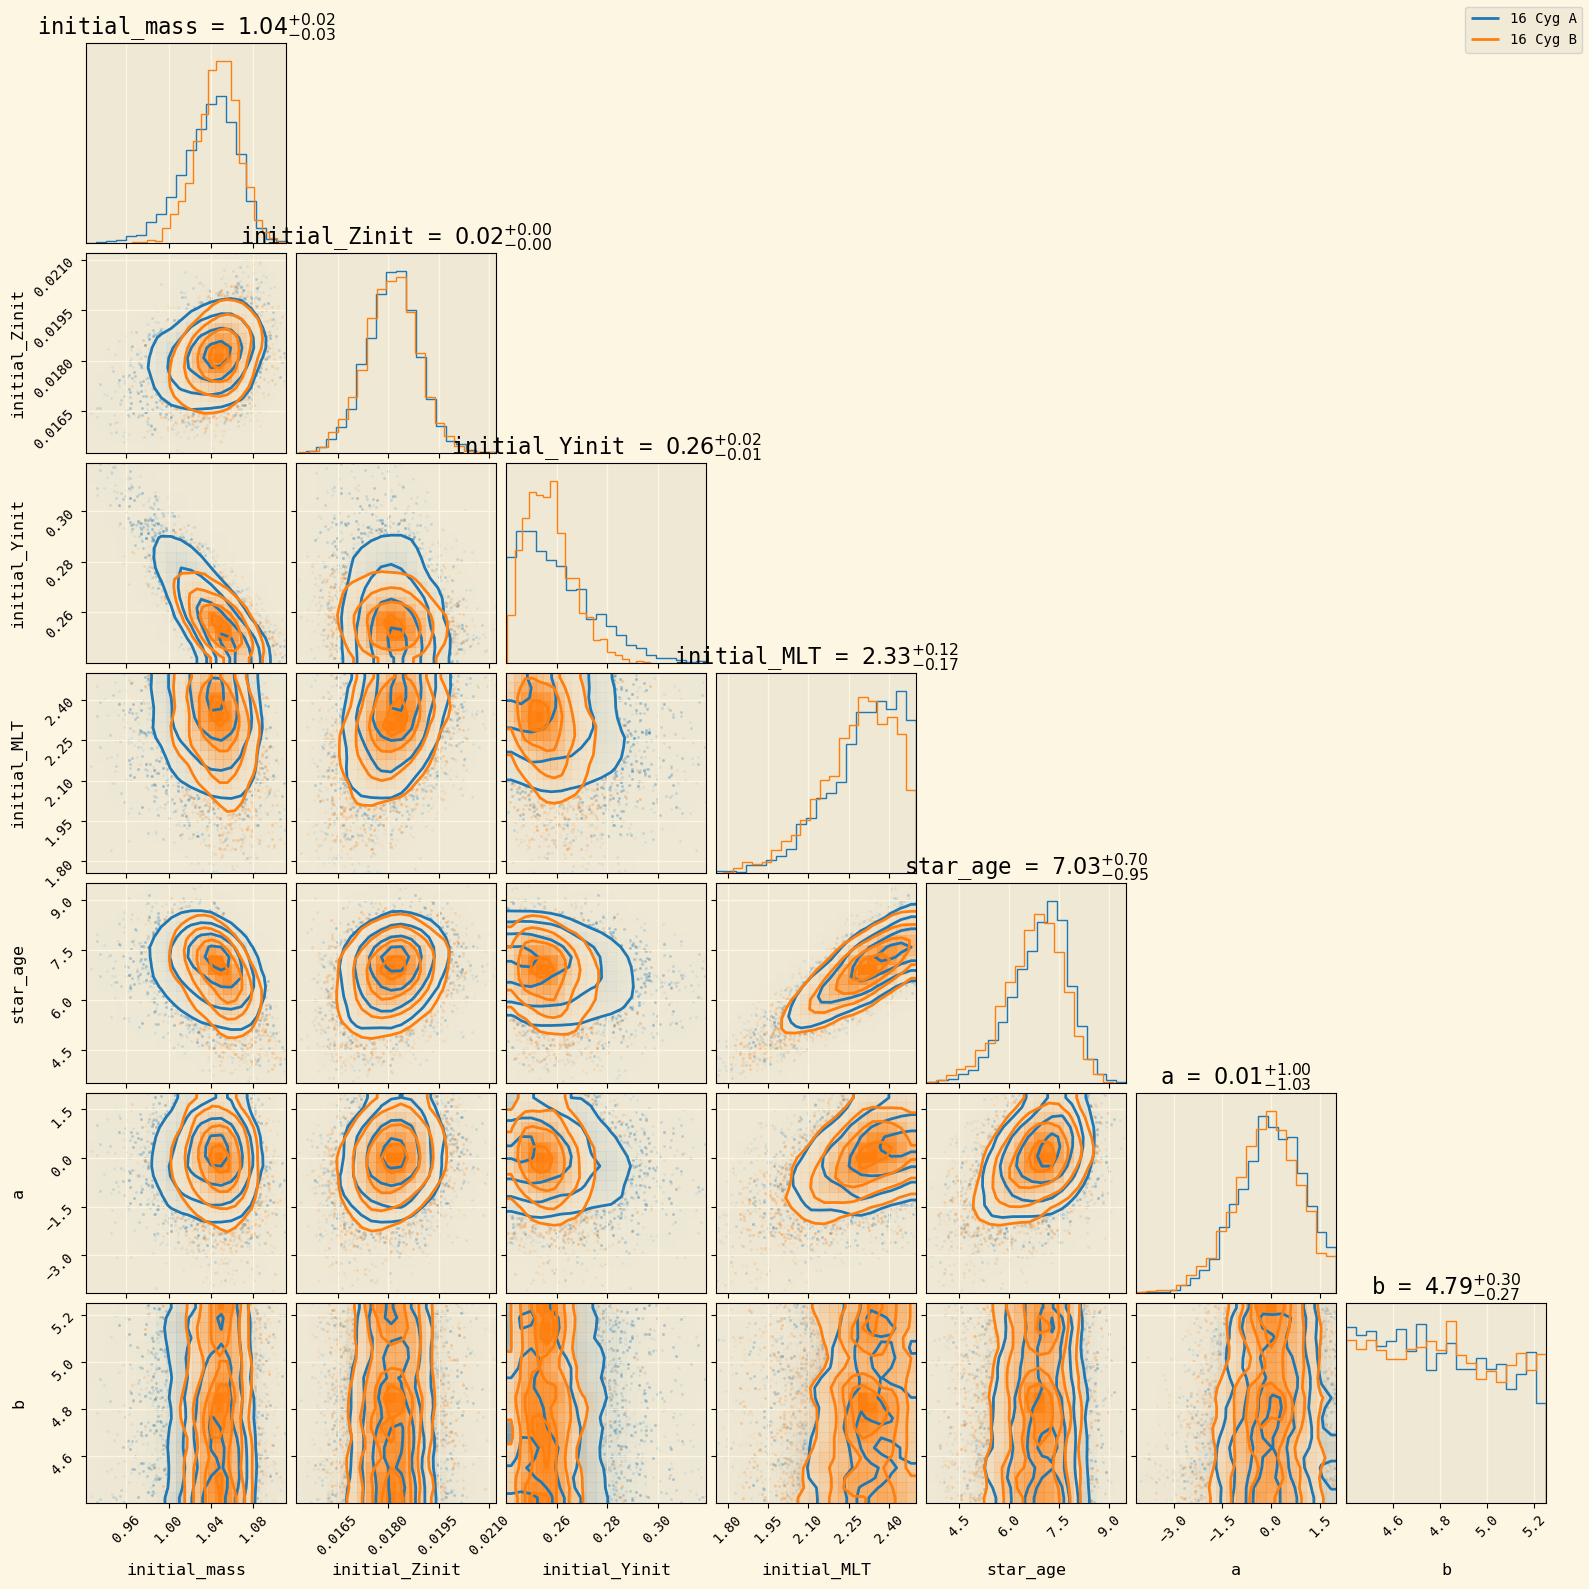

In [14]:
os.chdir(r"C:\Users\douga\Documents\Y4 Project")

with open('stars/16CygA/16CygA_uni_results.pkl', 'rb') as fp:
    results_A = pickle.load(fp)

with open('stars/16CygB/16CygB_uni_results.pkl', 'rb') as fp:
    results_B = pickle.load(fp)

# Extract posterior samples
# Check the structure of results if these keys are not correct
samples_A_uni = results_A["samples"]
samples_B_uni = results_B["samples"]

labels = [
    'initial_mass',
    'initial_Zinit',
    'initial_Yinit',
    'initial_MLT',
    'star_age',
    'a',
    'b'
]

# Plot both posterior distributions on the same figure
fig = corner.corner(
    samples_B_uni,
    labels=labels,
    color="tab:blue",
    smooth=True,
    hist_kwargs={"density": True},
    show_titles=True
)

corner.corner(
    samples_B_nonuni,
    labels=labels,
    color="tab:orange",
    smooth=True,
    hist_kwargs={"density": True},
    fig=fig,
    show_titles=False
)

# Add legend
handles = [
    plt.Line2D([], [], color="tab:blue", label="16 Cyg A"),
    plt.Line2D([], [], color="tab:orange", label="16 Cyg B")
]
fig.legend(handles=handles, loc="upper right")

plt.show()

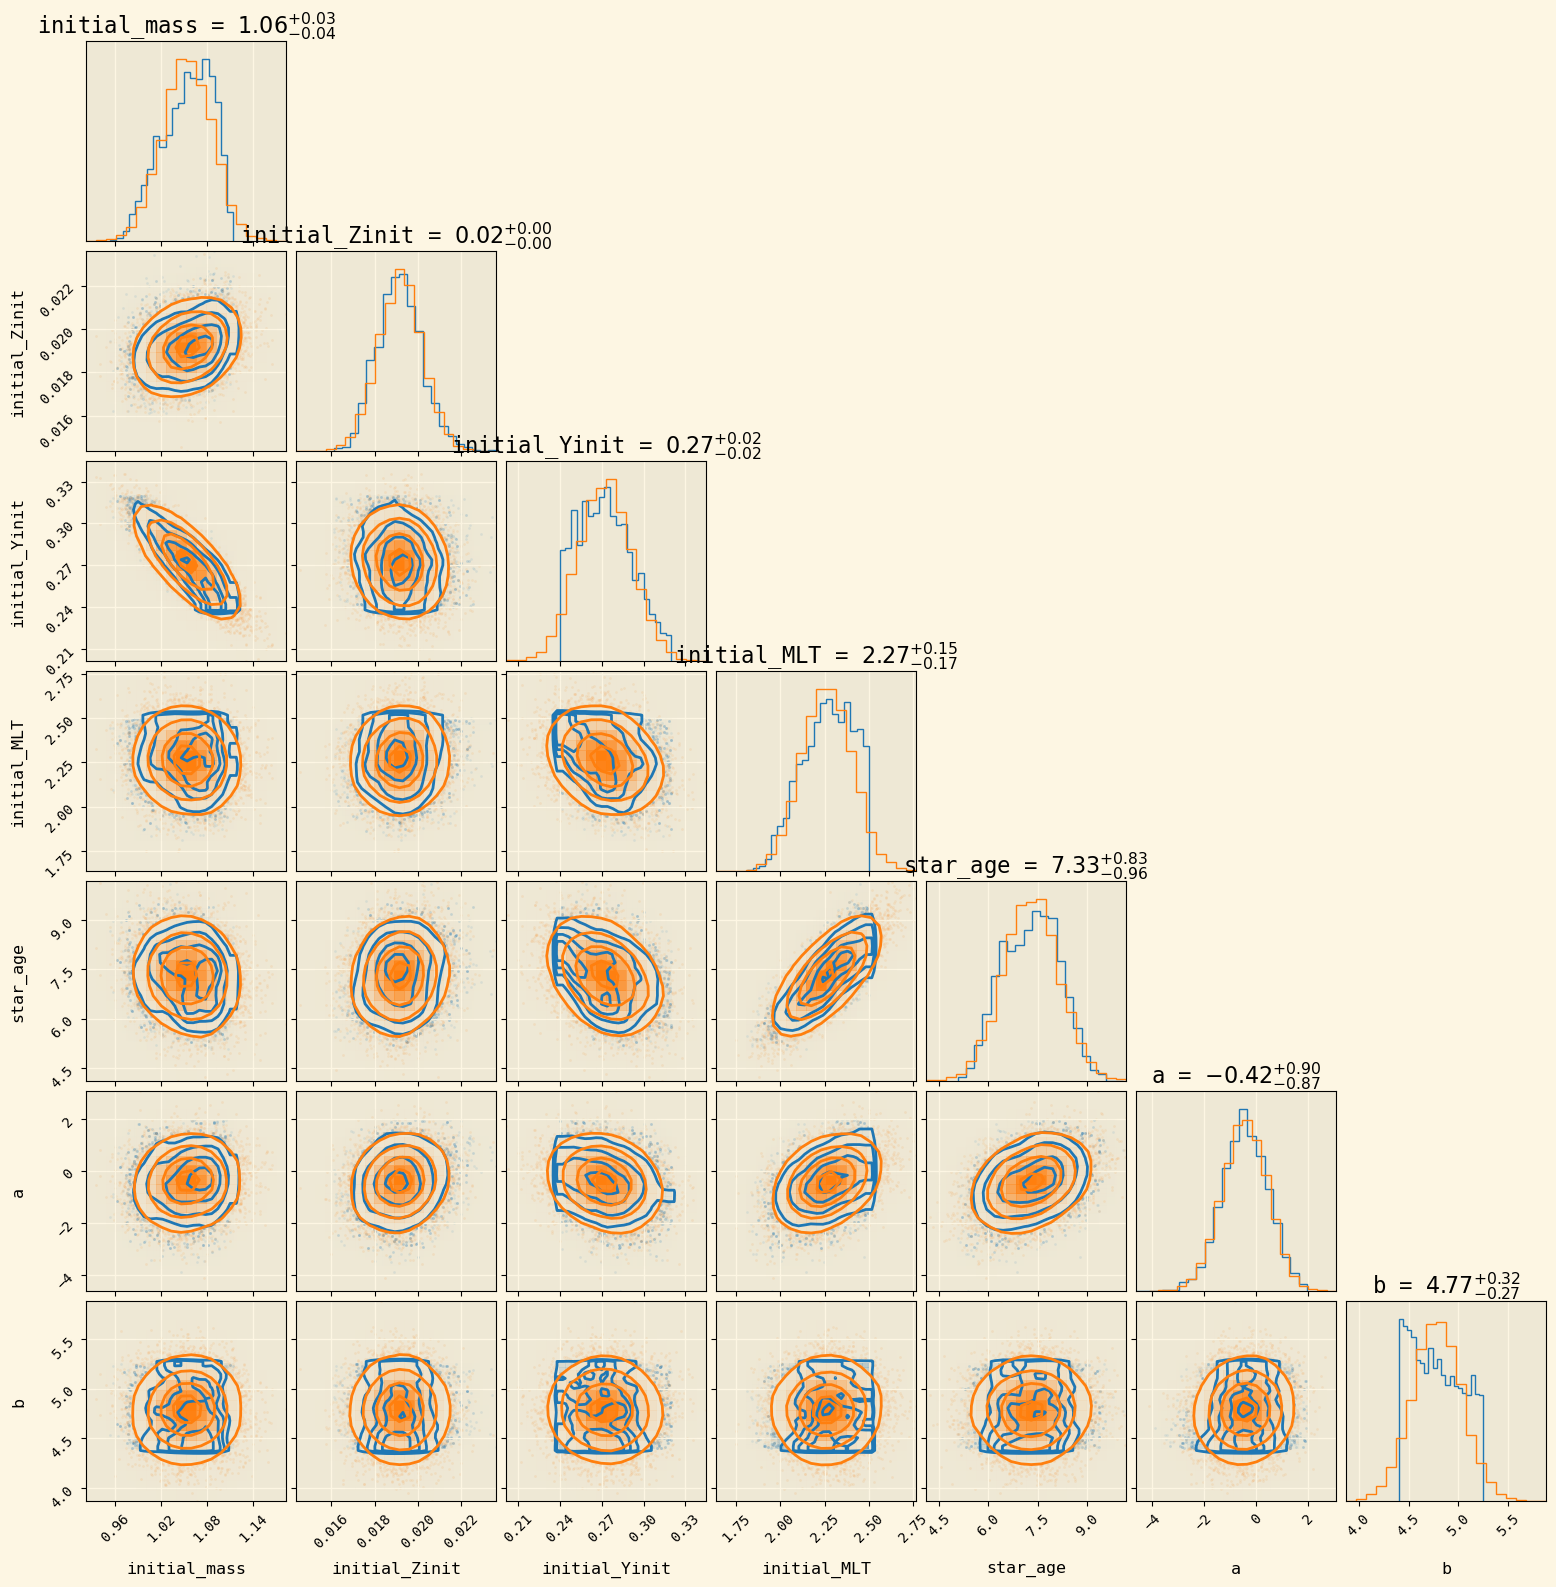

In [15]:
mu_A = np.mean(samples_A_uni, axis=0)
cov_A = np.cov(samples_A_uni, rowvar=False)

mu_B = np.mean(samples_B_uni, axis=0)
cov_B = np.cov(samples_B_uni, rowvar=False)

from scipy.stats import multivariate_normal

gaussian_A = multivariate_normal(mean=mu_A, cov=cov_A)
gaussian_B = multivariate_normal(mean=mu_B, cov=cov_B)

gaussian_samples_A = gaussian_A.rvs(
    size=len(samples_A_uni),
    random_state=42
)

gaussian_samples_B = gaussian_B.rvs(
    size=len(samples_B_uni),
    random_state=42
)

fig = corner.corner(
    samples_A_uni,
    labels=labels,
    color="tab:blue",
    smooth=True,
    hist_kwargs={"density": True},
    show_titles=True
)

corner.corner(
    gaussian_samples_A,
    labels=labels,
    color="tab:orange",
    smooth=True,
    hist_kwargs={"density": True},
    fig=fig,
    show_titles=False
)

plt.show()


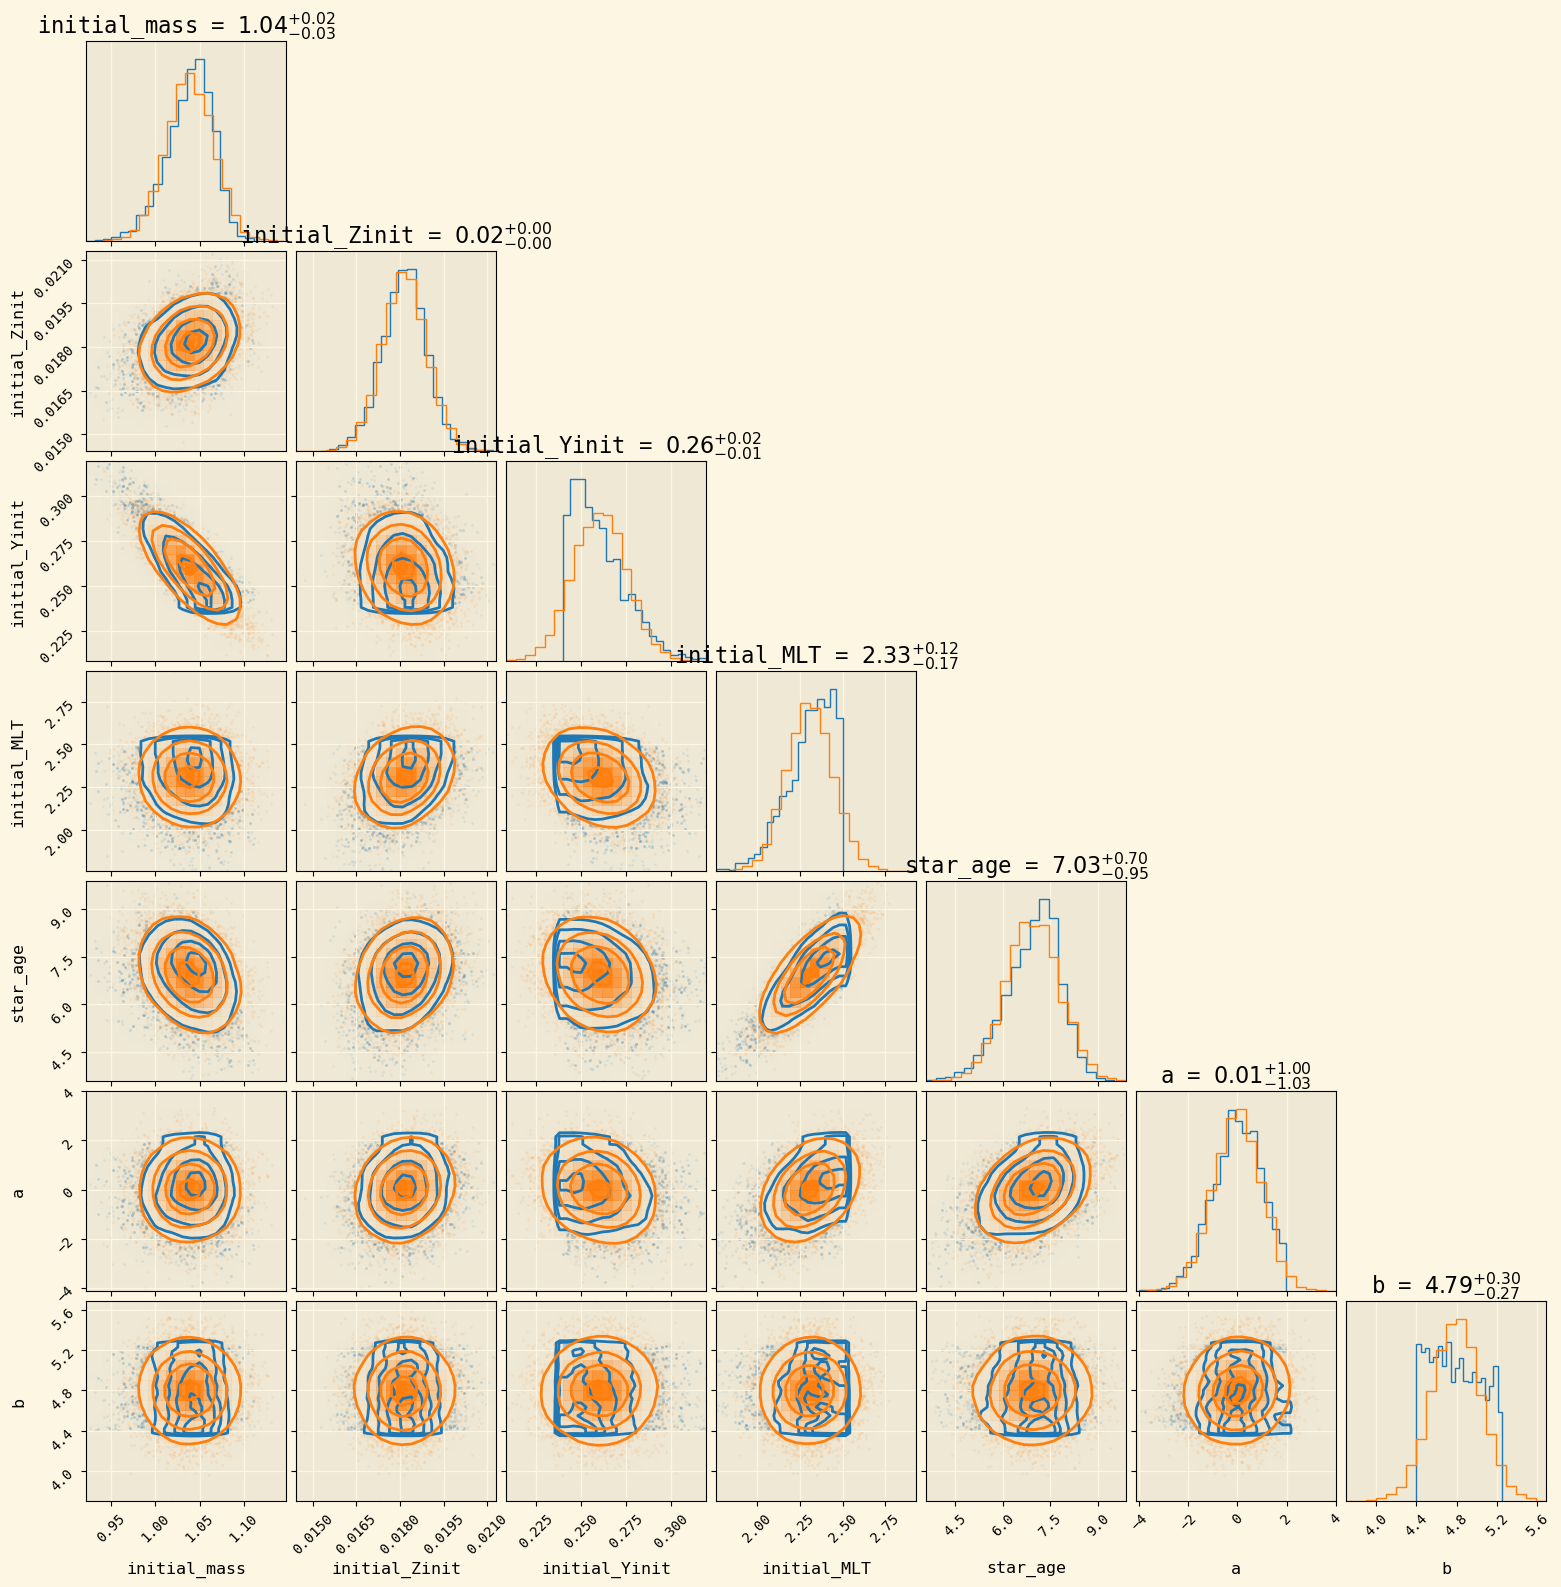

In [12]:
fig = corner.corner(
    samples_B_uni,
    labels=labels,
    color="tab:blue",
    smooth=True,
    hist_kwargs={"density": True},
    show_titles=True
)

corner.corner(
    gaussian_samples_B,
    labels=labels,
    color="tab:orange",
    smooth=True,
    hist_kwargs={"density": True},
    fig=fig,
    show_titles=False
)

plt.show()


In [17]:
from sklearn.mixture import GaussianMixture

# Number of components to test
k_values = range(1, 11)

# Store fitted models and their scores
models_A = {}
bic_A = []
aic_A = []

for k in k_values:

    gmm = GaussianMixture(
        n_components=k,
        covariance_type='full',
        n_init=5,
        random_state=42
    )

    gmm.fit(samples_A_uni)

    models_A[k] = gmm

    bic_A.append(gmm.bic(samples_A_uni))
    aic_A.append(gmm.aic(samples_A_uni))

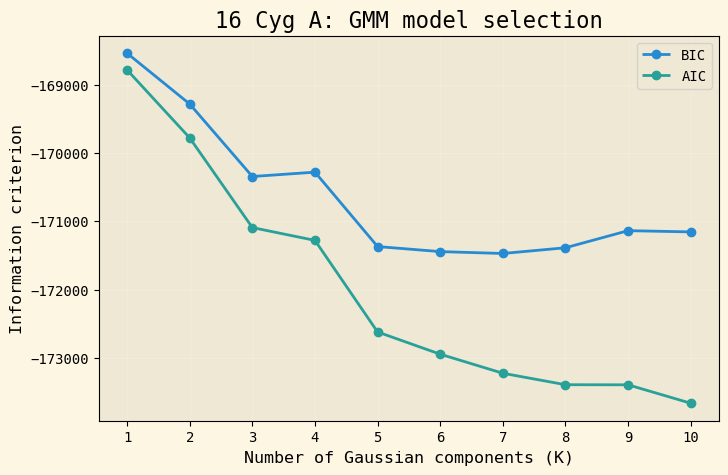

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    bic_A,
    marker='o',
    label='BIC'
)

plt.plot(
    k_values,
    aic_A,
    marker='o',
    label='AIC'
)

plt.xlabel('Number of Gaussian components (K)')
plt.ylabel('Information criterion')
plt.title('16 Cyg A: GMM model selection')

plt.xticks(list(k_values))
plt.legend()
plt.grid(alpha=0.3)

plt.show()

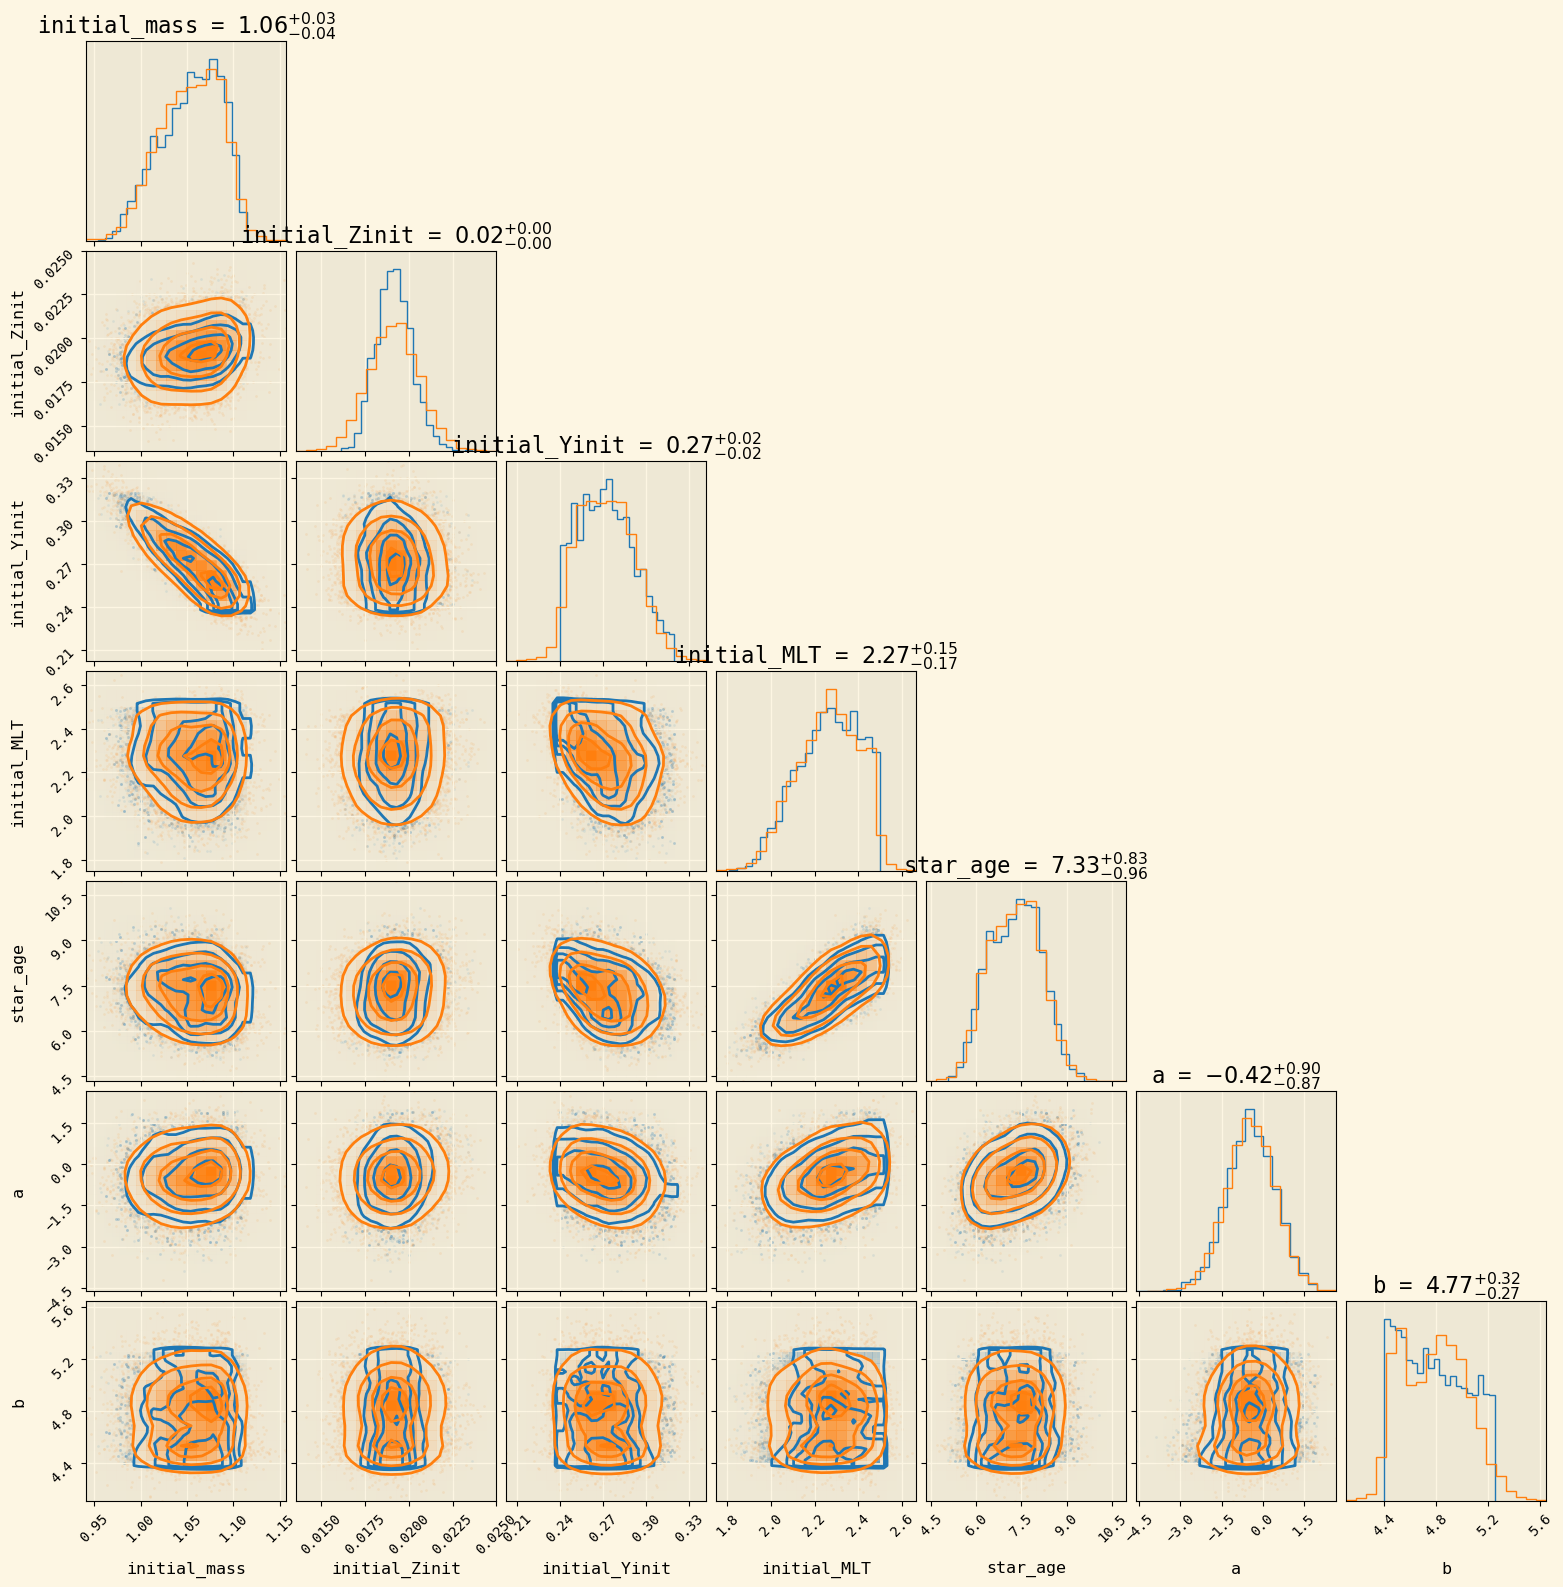

In [27]:
best_gmm_A = models_A[5]

gmm_samples_A = best_gmm_A.sample(
    n_samples=len(samples_A_uni)
)[0]
gmm_samples_A.shape
# (number_of_samples, 7)

fig = corner.corner(
    samples_A_uni,
    labels=labels,
    color="tab:blue",
    smooth=True,
    hist_kwargs={"density": True},
    show_titles=True
)

corner.corner(
    gmm_samples_A,
    labels=labels,
    color="tab:orange",
    smooth=True,
    hist_kwargs={"density": True},
    fig=fig,
    show_titles=False
)

plt.show()


In [29]:
from sklearn.mixture import BayesianGaussianMixture

bgmm_A = BayesianGaussianMixture(
    n_components=10,
    covariance_type='full',
    weight_concentration_prior_type='dirichlet_process',
    weight_concentration_prior=0.01,
    max_iter=1000,
    n_init=5,
    random_state=42
)

bgmm_A.fit(samples_A_uni)

,"n_components n_components: int, default=1The number of mixture components. Depending on the data and the valueof the `weight_concentration_prior` the model can decide to not useall the components by setting some component `weights_` to values veryclose to zero. The number of effective components is therefore smallerthan n_components.",10
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",1000
,"n_init n_init: int, default=1The number of initializations to perform. The result with the highestlower bound value on the likelihood is kept.",5
,"weight_concentration_prior weight_concentration_prior: float or None, default=NoneThe dirichlet concentration of each component on the weightdistribution (Dirichlet). This is commonly called gamma in theliterature. The higher concentration puts more mass inthe center and will lead to more components being active, while a lowerconcentration parameter will lead to more mass at the edge of themixture weights simplex. The value of the parameter must be greaterthan 0. If it is None, it's set to ``1. / n_components``.",0.01
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full' (each component has its own general covariance matrix),- 'tied' (all components share the same general covariance matrix),- 'diag' (each component has its own diagonal covariance matrix),- 'spherical' (each component has its own single variance).",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain on the likelihood (of the training data withrespect to the model) is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and thecovariances. String must be one of:- 'kmeans': responsibilities are initialized using kmeans.- 'k-means++': use the k-means++ method to initialize.- 'random': responsibilities are initialized randomly.- 'random_from_data': initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weight_concentration_prior_type weight_concentration_prior_type: {'dirichlet_process', 'dirichlet_distribution'}, default='dirichlet_process'String describing the type of the weight concentration prior.",'dirichlet_process'
,"mean_precision_prior mean_precision_prior: float or None, default=NoneThe precision prior on the mean distribution (Gaussian).Controls the extent of where means can be placed. Largervalues concentrate the cluster means around `mean_prior`.The value of the parameter must be greater than 0.If it is None, it is set to 1.",None


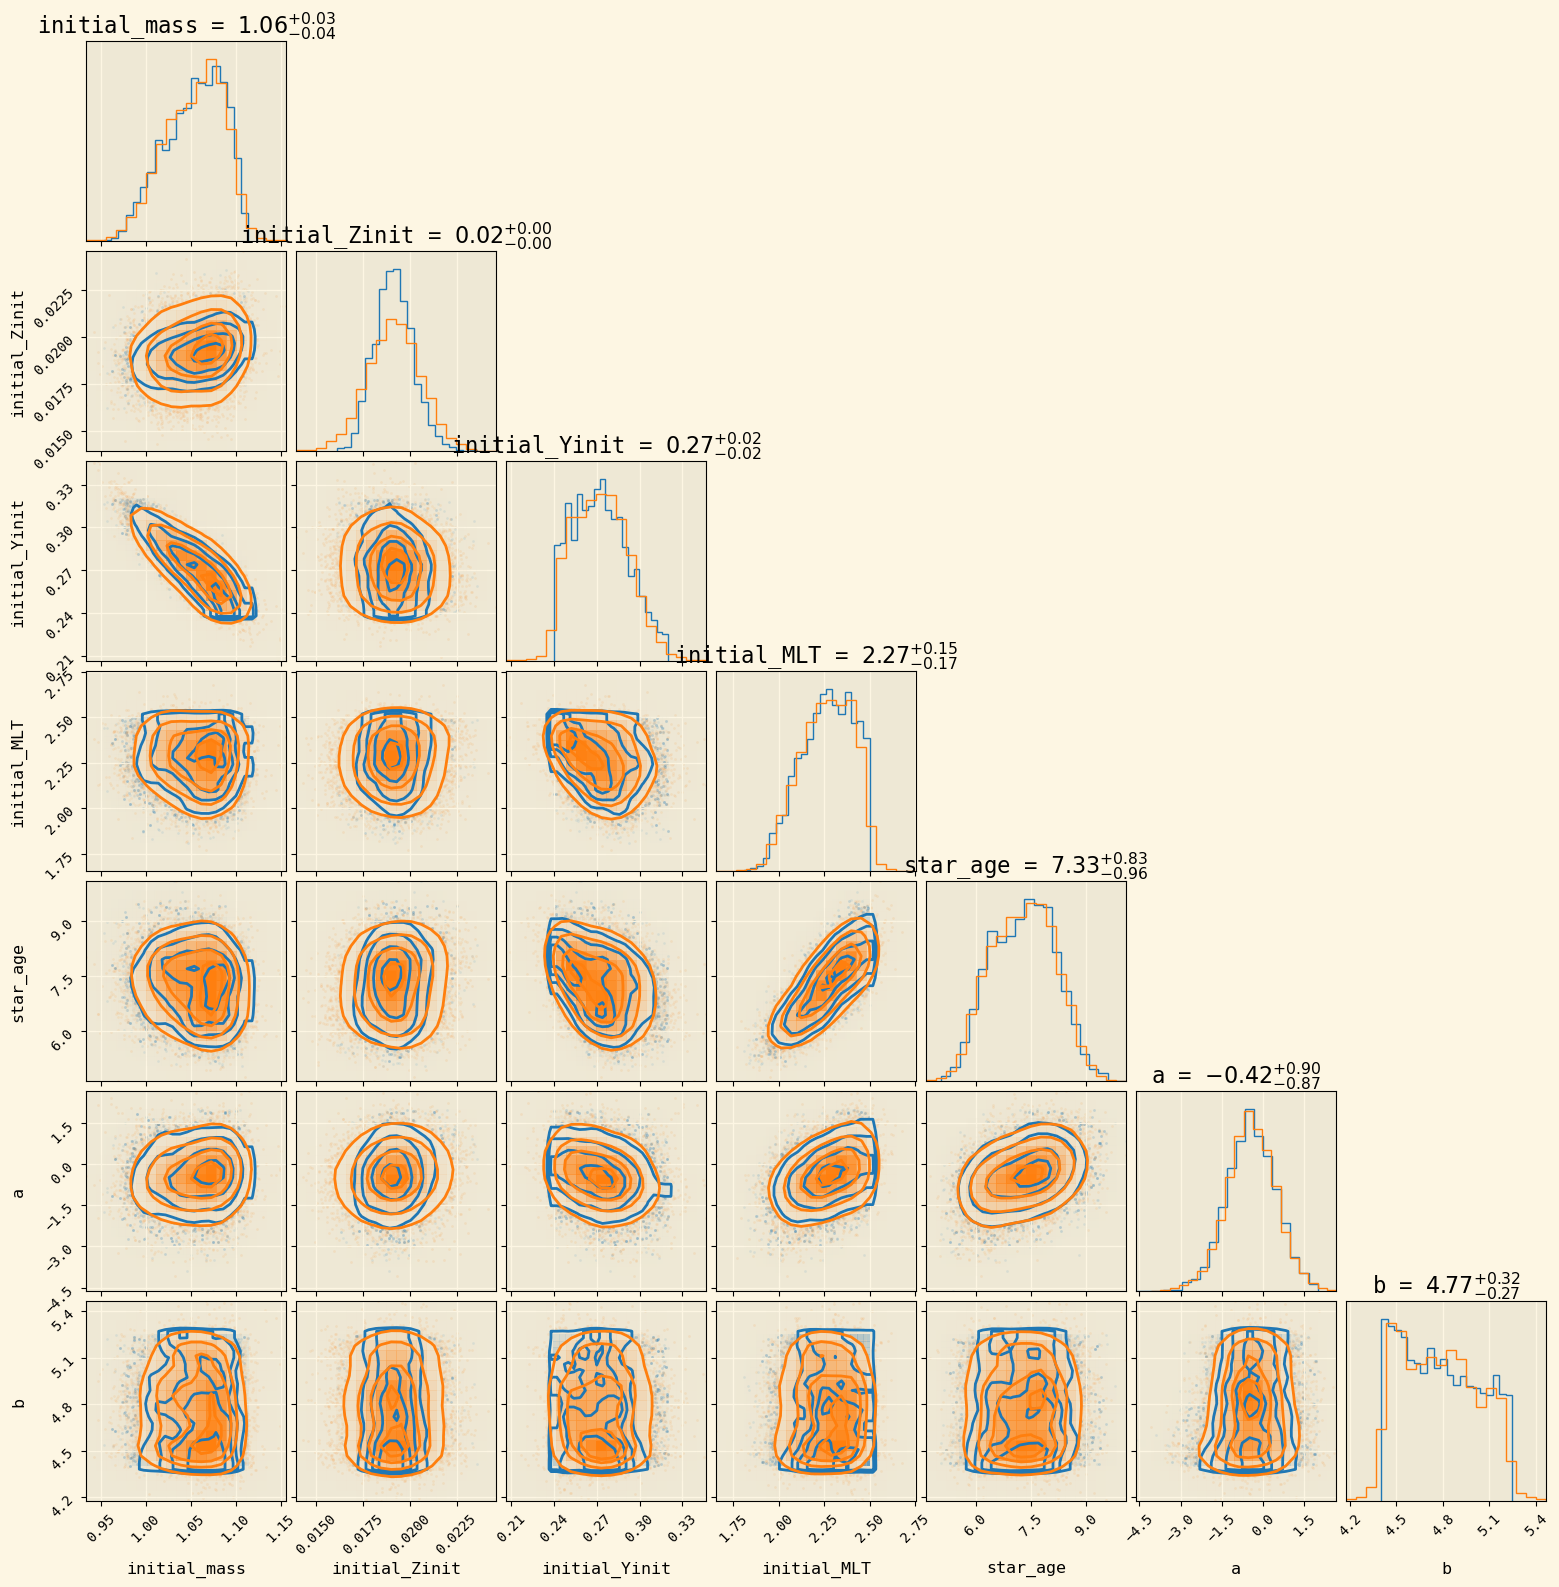

In [33]:
bgmm_samples_A = bgmm_A.sample(
    n_samples=len(samples_A_uni)
)[0]

fig = corner.corner(
    samples_A_uni,
    labels=labels,
    color="tab:blue",
    smooth=True,
    hist_kwargs={"density": True},
    show_titles=True
)

corner.corner(
    bgmm_samples_A,
    labels=labels,
    color="tab:orange",
    smooth=True,
    hist_kwargs={"density": True},
    fig=fig,
    show_titles=False
)

plt.show()

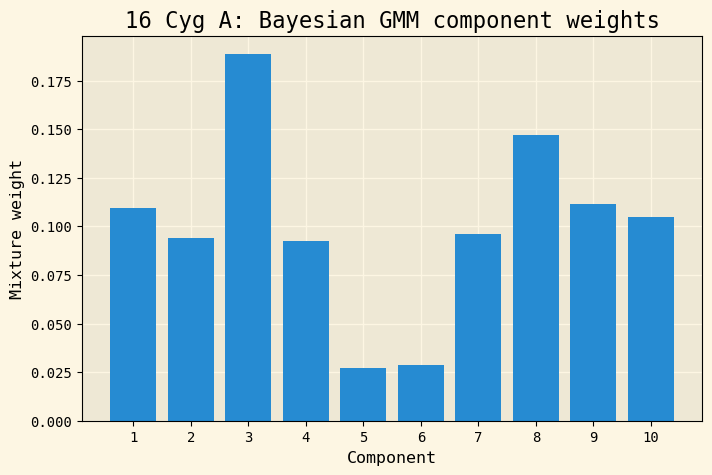

In [31]:
plt.figure(figsize=(8, 5))

plt.bar(
    np.arange(1, len(bgmm_A.weights_) + 1),
    bgmm_A.weights_
)

plt.xlabel('Component')
plt.ylabel('Mixture weight')
plt.title('16 Cyg A: Bayesian GMM component weights')

plt.xticks(np.arange(1, len(bgmm_A.weights_) + 1))
plt.show()